# Initialisation

In [2]:

from pulp import *
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import time

# Version avec coûts variables

In [1]:
def verifier_inegalite_triangulaire(dist):
    n = len(dist)
    for i in range(n):
        for j in range(n):
            for k in range(n):
                if dist[i][j] > dist[i][k] + dist[k][j]:
                    return False
    return True

def normaliser_pourcentage(valeur):
    return valeur / 100 if valeur > 1 else valeur

def generer_instance(
    n,
    x_max=1950,
    y_max=950,
    seed=None,
    pct_travaux=0.1,
    pct_interdites=0.05,
    pct_dependances=0.05,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
):
    while True:
        if seed is not None:
            np.random.seed(seed)
        
        x_coords = np.random.randint(50, x_max, size=n)
        y_coords = np.random.randint(50, y_max, size=n)
        coords = np.column_stack((x_coords, y_coords))

        dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
        
        if not verifier_inegalite_triangulaire(dist):
            seed = None
            continue

        

        couts = dist.copy()

        aretes = [(i, j) for i in range(n) for j in range(i + 1, n)]
        total_aretes = len(aretes)
        if total_aretes == 0:
            return coords.tolist(), couts.tolist(), [], [], []

        pct_travaux = normaliser_pourcentage(pct_travaux)
        pct_interdites = normaliser_pourcentage(pct_interdites)
        pct_dependances = normaliser_pourcentage(pct_dependances)

        nb_travaux = min(total_aretes, int(round(pct_travaux * total_aretes)))
        nb_interdites = min(total_aretes - nb_travaux, int(round(pct_interdites * total_aretes)))

        indices = np.arange(total_aretes)
        aretes_travaux = []
        aretes_interdites = []

        if nb_travaux > 0:
            indices_travaux = np.random.choice(indices, size=nb_travaux, replace=False)
            for idx in indices_travaux:
                i, j = aretes[idx]
                coef = np.random.uniform(coef_travaux_min, coef_travaux_max)
                valeur = int(round(dist[i, j] * coef))
                couts[i, j] = valeur
                couts[j, i] = valeur
                aretes_travaux.append((i, j))
            indices = np.setdiff1d(indices, indices_travaux, assume_unique=False)

        if nb_interdites > 0:
            indices_interdites = np.random.choice(indices, size=nb_interdites, replace=False)
            for idx in indices_interdites:
                i, j = aretes[idx]
                penalite = int(round(np.random.uniform(coef_interdit_min, coef_interdit_max)))
                valeur = dist[i, j] + penalite
                couts[i, j] = valeur
                couts[j, i] = valeur
                aretes_interdites.append((i, j))

        nb_dependances = max(0, int(round(pct_dependances * n)))
        dependances = set()
        if nb_dependances > 0:
            tentatives = 0
            max_tentatives = nb_dependances * 5
            while len(dependances) < nb_dependances and tentatives < max_tentatives:
                i = np.random.randint(0, n)
                j = np.random.randint(0, n)
                if i != j and (i, j) not in dependances:
                    dependances.add((i, j))
                tentatives += 1

        return coords.tolist(), couts.tolist(), aretes_travaux, aretes_interdites, list(dependances)

In [3]:
n = 20
coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
    n=n,
    pct_travaux=0.05,
    pct_interdites=0.02,
    pct_dependances=0.15,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
    seed=None,
)

print(f"Instance générée : {n} villes")
print(f"Nombre total d'arêtes : {n * (n - 1) // 2}")
print(f"Nombre d'arêtes en travaux : {len(aretes_travaux)}")
print(f"Nombre d'arêtes interdites : {len(aretes_interdites)}")
print(f"Nombre de dépendances : {len(dependances)}")
print(f"Dépendances : {dependances}")
print(f"Coordonnées : {coords}")

Instance générée : 20 villes
Nombre total d'arêtes : 190
Nombre d'arêtes en travaux : 10
Nombre d'arêtes interdites : 4
Nombre de dépendances : 3
Dépendances : [(10, 15), (0, 13), (14, 16)]
Coordonnées : [[1044, 450], [53, 661], [105, 507], [418, 103], [913, 107], [118, 900], [1262, 529], [1270, 606], [853, 68], [1738, 51], [781, 332], [1751, 338], [563, 672], [1354, 281], [413, 433], [1826, 114], [824, 538], [299, 552], [1938, 108], [1520, 617]]


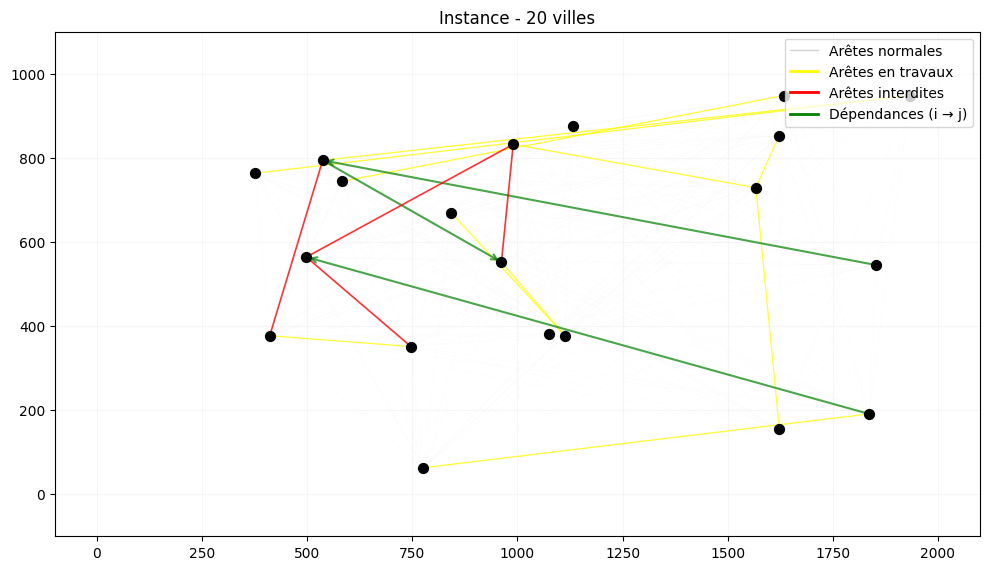

In [8]:
coords = np.array(coords)
from matplotlib.lines import Line2D

all_segments = [coords[[i, j]] for i in range(n) for j in range(i + 1, n)]
segments_travaux = [coords[[i, j]] for i, j in aretes_travaux]
segments_interdites = [coords[[i, j]] for i, j in aretes_interdites]

fig, ax = plt.subplots(figsize=(10, 8))
ax.add_collection(LineCollection(all_segments, colors='grey', linewidths=0.1, alpha=0.1, zorder=1))
if segments_travaux:
    ax.add_collection(LineCollection(segments_travaux, colors='yellow', linewidths=0.9, alpha=0.8, zorder=2))
if segments_interdites:
    ax.add_collection(LineCollection(segments_interdites, colors='red', linewidths=1.2, alpha=0.8, zorder=3))

if dependances:
    for i, j in dependances:
        ax.annotate('', xy=coords[j], xytext=coords[i],
                   arrowprops=dict(arrowstyle='->', lw=1.5, color='green', alpha=0.7), zorder=2)

ax.scatter(coords[:, 0], coords[:, 1], s=50, c='black', zorder=5)

legend_elements = [
    Line2D([0], [0], color='lightgray', lw=1, label='Arêtes normales'),
    Line2D([0], [0], color='yellow', lw=2, label='Arêtes en travaux'),
    Line2D([0], [0], color='red', lw=2, label='Arêtes interdites'),
    Line2D([0], [0], color='green', lw=2, label='Dépendances (i → j)'),
]
ax.legend(handles=legend_elements, loc='upper right')

ax.grid(True, alpha=0.1)
ax.set_title(f'Instance - {n} villes')
ax.set_xlim(-100, 2100)
ax.set_ylim(-100, 1100)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

Statut : Optimal
Coût optimal : 541862.00
Tournée : [0, 14, 13, 7, 1, 4, 16, 8, 6, 19, 3, 11, 17, 15, 2, 5, 10, 18, 12, 9, 0]
Temps de résolution : 55.4409 s


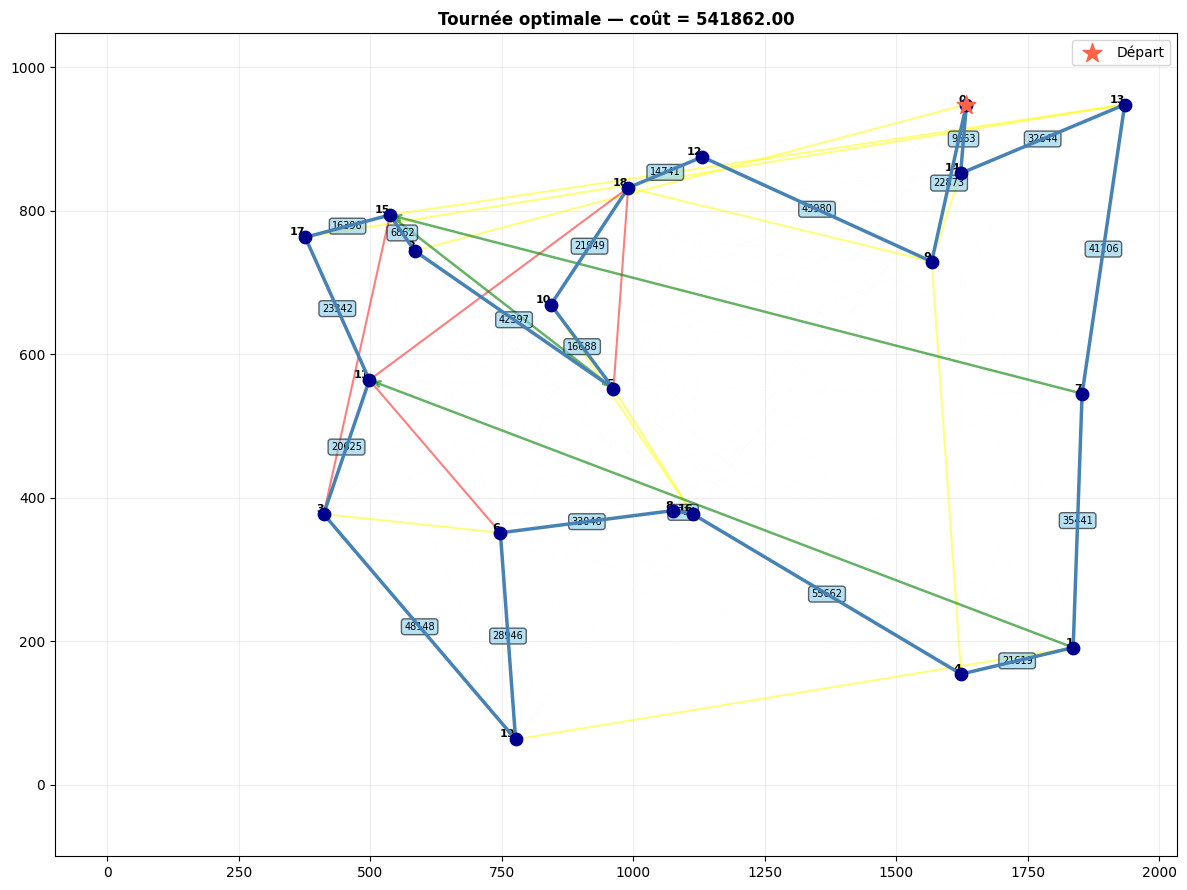

In [ ]:
def resoudre_tsp_plne(couts, coords=None, aretes_travaux=None, aretes_interdites=None, dependances=None):
    n = len(couts)
    villes = range(n)

    prob = LpProblem("TSP_Couts_Variables", LpMinimize)

    x = LpVariable.dicts("x", (villes, villes), cat="Binary")
    p = LpVariable.dicts("p", range(1, n), lowBound=1, upBound=n - 1, cat="Continuous")

    prob += lpSum(couts[i][j] * x[i][j] for i in villes for j in villes if i != j)

    for i in villes:
        prob += lpSum(x[i][j] for j in villes if j != i) == 1
        prob += lpSum(x[j][i] for j in villes if j != i) == 1

    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                prob += p[i] - p[j] + n * x[i][j] <= n - 1

    if dependances:
        for i, j in dependances:
            if 0 < i < n and 0 < j < n and i != j:
                prob += p[i] - p[j] <= -1
            elif i == 0 and 0 < j < n:
                pass
            elif 0 < i < n and j == 0:
                prob += p[i] >= 1

    debut = time.time()
    prob.solve(PULP_CBC_CMD(msg=0))
    duree = time.time() - debut

    if LpStatus[prob.status] != "Optimal":
        print(f"Statut du solveur : {LpStatus[prob.status]}")
        return None, None, duree

    cout = value(prob.objective)

    tournee = [0]
    ville_courante = 0
    for _ in range(n - 1):
        for j in villes:
            if j != ville_courante and value(x[ville_courante][j]) > 0.5:
                tournee.append(j)
                ville_courante = j
                break

    print(f"Statut : {LpStatus[prob.status]}")
    print(f"Coût optimal : {cout:.2f}")
    print(f"Tournée : {tournee + [tournee[0]]}")
    print(f"Temps de résolution : {duree:.4f} s")

    return tournee, cout, duree


def afficher_tournee(coords, tournee, dist, couts=None, aretes_travaux=None, aretes_interdites=None, dependances=None, cout=None):
    titre = "Tournée optimale"
    if cout is not None:
        titre += f" — coût = {cout:.2f}"

    fig, ax = plt.subplots(figsize=(12, 9))

    coords_np = np.array(coords)
    all_segments = [coords_np[[i, j]] for i in range(len(coords)) for j in range(i + 1, len(coords))]
    ax.add_collection(LineCollection(all_segments, colors='lightgray', linewidths=0.1, alpha=0.1))

    if aretes_travaux:
        segments_travaux = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(segments_travaux, colors='yellow', linewidths=1.5, alpha=0.5))

    if aretes_interdites:
        segments_interdites = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(segments_interdites, colors='red', linewidths=1.5, alpha=0.5))

    if dependances:
        for i, j in dependances:
            ax.annotate('', xy=coords_np[j], xytext=coords_np[i],
                       arrowprops=dict(arrowstyle='->', lw=1.8, color='green', alpha=0.6), zorder=3)

    for k in range(len(tournee)):
        i = tournee[k]
        j = tournee[(k + 1) % len(tournee)]
        ax.plot([coords_np[i, 0], coords_np[j, 0]],
               [coords_np[i, 1], coords_np[j, 1]],
               color="steelblue", linewidth=2.5, zorder=5)

        mid_x = (coords_np[i, 0] + coords_np[j, 0]) / 2
        mid_y = (coords_np[i, 1] + coords_np[j, 1]) / 2
        distance = dist[i][j]
        ax.text(mid_x, mid_y, f'{distance:.0f}', fontsize=7, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='skyblue', alpha=0.6))

    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c="darkblue", s=80, zorder=6)
        ax.annotate(f"{i}", (x, y), fontsize=8, ha='right', va='bottom', fontweight='bold')

    ax.scatter([coords_np[0, 0]], [coords_np[0, 1]], c="tomato", s=200, zorder=7, marker='*', label="Départ")

    ax.set_title(titre, fontsize=12, fontweight='bold')
    ax.set_xlim(-100, max(coords_np[:, 0]) + 100)
    ax.set_ylim(-100, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()


tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites, dependances)

if tournee is not None:
    afficher_tournee(coords, tournee, dist, couts=dist, aretes_travaux=aretes_travaux,
                    aretes_interdites=aretes_interdites, dependances=dependances, cout=cout)


Résolution exacte pour n=10
Instance 1/3... Statut : Optimal
Coût optimal : 460559.00
Tournée : [0, 3, 7, 8, 6, 1, 4, 9, 2, 5, 0]
Temps de résolution : 0.1641 s
OK - 0.1641s
Instance 2/3... Statut : Optimal
Coût optimal : 425026.00
Tournée : [0, 9, 8, 4, 2, 7, 5, 6, 1, 3, 0]
Temps de résolution : 1.2830 s
OK - 1.2830s
Instance 3/3... Statut : Optimal
Coût optimal : 423703.00
Tournée : [0, 1, 8, 7, 2, 6, 5, 4, 9, 3, 0]
Temps de résolution : 0.5595 s
OK - 0.5595s

Résolution exacte pour n=15
Instance 1/3... Statut : Optimal
Coût optimal : 441181.00
Tournée : [0, 4, 1, 13, 6, 8, 3, 11, 5, 7, 2, 14, 9, 12, 10, 0]
Temps de résolution : 3.0200 s
OK - 3.0200s
Instance 2/3... Statut : Optimal
Coût optimal : 533389.00
Tournée : [0, 10, 3, 11, 13, 5, 6, 2, 7, 4, 14, 8, 9, 12, 1, 0]
Temps de résolution : 10.6955 s
OK - 10.6955s
Instance 3/3... Statut : Optimal
Coût optimal : 507124.00
Tournée : [0, 14, 1, 7, 2, 5, 6, 10, 12, 4, 8, 13, 9, 11, 3, 0]
Temps de résolution : 14.6226 s
OK - 14.6226s

R

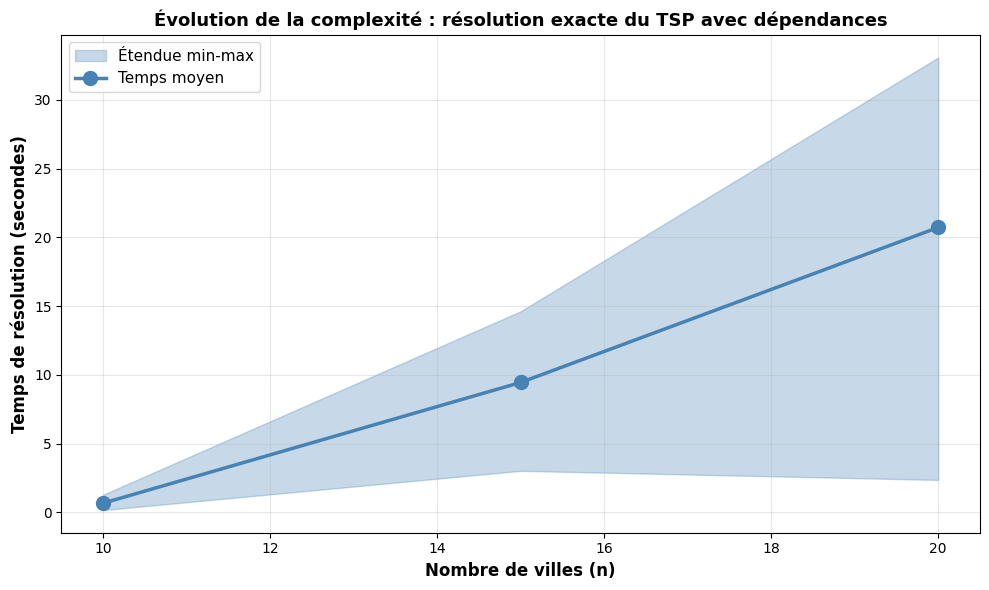


ANALYSE
• Croissance exponentielle observée : temps → infini rapidement
• Au-delà de n=25, résolution exacte devient impraticable
• Dépendances ajoutent des contraintes supplémentaires
• Nécessité d'algorithmes approchés/métaheuristiques pour:
  - Instances réalistes (n > 50)
  - Optimisation en temps acceptable


In [ ]:
import pandas as pd

tailles_n = [10, 15, 20]
nb_instances_par_taille = 3

resultats = []

for n in tailles_n:
    temps_par_instance = []

    print(f"\n{'='*50}")
    print(f"Résolution exacte pour n={n}")
    print(f"{'='*50}")

    for run in range(nb_instances_par_taille):
        coords, couts, aretes_travaux, aretes_interdites, dependances = generer_instance(
            n=n,
            pct_travaux=0.05,
            pct_interdites=0.02,
            pct_dependances=0.10,
            seed=42 + run
        )

        print(f"Instance {run+1}/{nb_instances_par_taille}...", end=" ", flush=True)
        tournee, cout, duree = resoudre_tsp_plne(couts, coords, aretes_travaux, aretes_interdites, dependances)

        if tournee is not None:
            print(f"OK - {duree:.4f}s")
            temps_par_instance.append(duree)
        else:
            print("Échec")

    if temps_par_instance:
        temps_moyen = np.mean(temps_par_instance)
        temps_min = np.min(temps_par_instance)
        temps_max = np.max(temps_par_instance)

        resultats.append({
            'n': n,
            'Temps moyen (s)': f"{temps_moyen:.4f}",
            'Temps min (s)': f"{temps_min:.4f}",
            'Temps max (s)': f"{temps_max:.4f}",
            'Arêtes': n * (n - 1) // 2
        })

df_resultats = pd.DataFrame(resultats)
print("\n" + "="*60)
print("RÉSULTATS - Complexité de la résolution exacte")
print("="*60)
print(df_resultats.to_string(index=False))

temps_moyens = [float(r['Temps moyen (s)']) for r in resultats]
temps_mins = [float(r['Temps min (s)']) for r in resultats]
temps_maxs = [float(r['Temps max (s)']) for r in resultats]
n_values = [r['n'] for r in resultats]

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(n_values, temps_mins, temps_maxs, alpha=0.3, color='steelblue', label='Étendue min-max')
ax.plot(n_values, temps_moyens, 'o-', linewidth=2.5, markersize=10, color='steelblue', label='Temps moyen')
ax.set_xlabel('Nombre de villes (n)', fontsize=12, fontweight='bold')
ax.set_ylabel('Temps de résolution (secondes)', fontsize=12, fontweight='bold')
ax.set_title('Évolution de la complexité : résolution exacte du TSP avec dépendances', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()